# 03 – Silver Transformation (Task C01 · C02 · C03)

**CommerceFlow 360** · Người phụ trách: **Duy Lê** · Mục báo cáo: 3.2, 3.4, 3.7

| Task | Nội dung | Đầu ra |
|---|---|---|
| C01 | Cài dbt Core + dbt-duckdb, khai báo `sources.yml` trỏ tới `bronze_*`, chạy `dbt debug` | `dbt_project/dbt_project.yml`, `dbt_project/models/sources.yml`, `dbt_project/profiles.yml.example` |
| C02 | 9 model `silver_*` cho 9 bảng Olist (+ `silver_holidays` hỗ trợ `dim_date`) | `dbt_project/models/silver/silver_*.sql` |
| C03 | dbt tests: unique, not_null, accepted_values, relationships + test tùy chỉnh | `dbt_project/models/silver/schema.yml`, `dbt_project/tests/test_silver_*.sql` |

**Đầu vào:** file `commerceflow.duckdb` đã có các bảng `bronze_*` do notebook `02_Bronze_Ingestion.ipynb` (Task B01) tạo ra.
Notebook chạy được trên Google Colab và máy cá nhân, không phụ thuộc đường dẫn riêng của thành viên nào.

## 1. Chuẩn bị môi trường

In [1]:
# Trên Colab: clone repository và cài thư viện (bỏ qua khi chạy trong repository trên máy cá nhân)
import sys
from pathlib import Path

IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    if not Path('/content/CommerceFlow360').exists():
        !git clone -q https://github.com/huyenpiano1711/CommerceFlow360.git /content/CommerceFlow360
    %cd /content/CommerceFlow360
    %pip install -q -r requirements.txt

PROJECT_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'dbt_project' / 'dbt_project.yml').is_file())
sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd
from src.ingestion.bronze_ingestion import RAW_FILES
from src.utils.project import (DUCKDB_PATH, PROJECT_ROOT, TABLE_DIR, ensure_dbt_profile,
                               load_test_results, query, run_dbt)

pd.set_option('display.max_colwidth', 120)
DQ_DIR = PROJECT_ROOT / 'docs' / 'data_quality'
print('PROJECT_ROOT:', PROJECT_ROOT)
print('DUCKDB_PATH :', DUCKDB_PATH)

PROJECT_ROOT: D:\CommerceFlow360
DUCKDB_PATH : D:\CommerceFlow360\commerceflow.duckdb


## 2. Kiểm tra tầng Bronze đầu vào

Silver đọc các bảng Bronze qua `source('bronze', ...)` khai báo trong `models/sources.yml`.
Nếu thiếu bảng, hãy chạy `02_Bronze_Ingestion.ipynb` trước
(hoặc tải bản sao lưu `commerceflow_YYYYMMDD.duckdb` rồi đổi tên thành `commerceflow.duckdb`).

In [2]:
existing = set(query("select table_name from information_schema.tables where table_schema = 'main'")['table_name']) \
    if DUCKDB_PATH.exists() else set()
missing_bronze = [t for t in RAW_FILES if t not in existing]
assert not missing_bronze, f'Thiếu bảng Bronze: {missing_bronze}. Chạy 02_Bronze_Ingestion.ipynb trước.'
bronze_counts = pd.concat([query(f"select '{t}' as bang_bronze, count(*) as so_dong from {t}") for t in RAW_FILES])
bronze_counts

,bang_bronze,so_dong
0,bronze_customers,99441
0,bronze_geolocation,1000163
0,bronze_order_items,112650
0,bronze_order_payments,103886
0,bronze_order_reviews,99224
0,bronze_orders,99441
0,bronze_products,32951
0,bronze_sellers,3095
0,bronze_product_category_name_translation,71
0,bronze_holidays,27


## 3. C01 – Cấu hình dbt và `dbt debug`

`profiles.yml` thật không được commit. Nếu máy chưa có `~/.dbt/profiles.yml`, notebook sao chép từ `profiles.yml.example`;
đường dẫn DuckDB lấy từ biến môi trường `DUCKDB_PATH` (đặt khi import `src.utils.project`).

In [3]:
print(ensure_dbt_profile().read_text(encoding='utf-8'))
_ = run_dbt('debug')

# =============================================================================
# Mẫu cấu hình kết nối dbt -> DuckDB cho CommerceFlow 360.
# KHÔNG commit file profiles.yml thật. Cách dùng:
#   1) Sao chép file này thành ~/.dbt/profiles.yml  (hoặc vào thư mục bất kỳ
#      rồi chạy dbt với --profiles-dir <thư mục đó>).
#   2) Đặt biến môi trường DUCKDB_PATH trỏ tới file commerceflow.duckdb
#      (notebook 03_Silver_Transformation.ipynb tự làm hai bước này).
# Nếu không đặt DUCKDB_PATH, dbt dùng ../commerceflow.duckdb tính từ thư mục
# dbt_project/, tức là file commerceflow.duckdb ở thư mục gốc repository.
# =============================================================================
commerceflow360:
  target: dev
  outputs:
    dev:
      type: duckdb
      path: "{{ env_var('DUCKDB_PATH', '../commerceflow.duckdb') }}"
      schema: main
      threads: 4

$ dbt debug


16:50:12  Running with dbt=1.12.6
16:50:12  dbt version: 1.12.6
16:50:12  python version: 3.13.1
16:50:12  python path: D:\CommerceFlow360\.venv\Scripts\python.exe
16:50:12  os info: Windows-11-10.0.26200-SP0
16:50:13  Using profiles dir at C:\Users\sunah\.dbt
16:50:13  Using profiles.yml file at C:\Users\sunah\.dbt\profiles.yml
16:50:13  Using dbt_project.yml file at D:\CommerceFlow360\dbt_project\dbt_project.yml
16:50:13  adapter type: duckdb
16:50:13  adapter version: 1.11.1
16:50:13  Configuration:
16:50:13    profiles.yml file [OK found and valid]
16:50:13    dbt_project.yml file [OK found and valid]
16:50:13  Required dependencies:
16:50:13   - git [OK found]

16:50:13  Connection:
16:50:13    database: commerceflow
16:50:13    schema: main
16:50:13    path: D:\CommerceFlow360\commerceflow.duckdb
16:50:13    config_options: None
16:50:13    extensions: None
16:50:13    settings: {}
16:50:13    external_root: .
16:50:13    use_credential_provider: None
16:50:13    attach: None
16:

## 4. C02 – Xây dựng các model Silver

Mỗi model đọc một bảng Bronze, ép kiểu, chuẩn hóa chuỗi, xử lý giá trị thiếu/không hợp lệ và khử trùng theo grain.
`silver_products` phụ thuộc `silver_product_category_name_translation` (đã bổ sung danh mục thiếu bản dịch).

In [4]:
_ = run_dbt('run', '--select', 'silver')

$ dbt run --select silver


16:50:37  Running with dbt=1.12.6
16:50:39  Registered adapter: duckdb=1.11.1
16:50:40  Unable to do partial parsing because profile has changed
16:50:49  Found 22 models, 89 data tests, 10 sources, 522 macros
16:50:49  
16:50:49  Concurrency: 4 threads (target='dev')
16:50:49  
16:50:50  1 of 10 START sql table model main.silver_customers ............................ [RUN]
16:50:50  4 of 10 START sql table model main.silver_order_items .......................... [RUN]
16:50:50  2 of 10 START sql table model main.silver_geolocation .......................... [RUN]
16:50:50  3 of 10 START sql table model main.silver_holidays ............................. [RUN]
16:50:52  3 of 10 OK created sql table model main.silver_holidays ........................ [OK in 1.55s]
16:50:52  5 of 10 START sql table model main.silver_order_payments ....................... [RUN]
16:50:57  1 of 10 OK created sql table model main.silver_customers ....................... [OK in 6.80s]
16:50:57  6 of 10 START s

In [5]:
SILVER_TABLES = ['silver_orders', 'silver_order_items', 'silver_order_payments', 'silver_order_reviews',
                 'silver_customers', 'silver_sellers', 'silver_products',
                 'silver_product_category_name_translation', 'silver_geolocation', 'silver_holidays']
schema_df = query("""
    select table_name as bang, count(*) as so_cot,
           string_agg(column_name || ' ' || data_type, ', ' order by ordinal_position) as cot_va_kieu
    from information_schema.columns
    where table_name like 'silver_%'
    group by table_name order by table_name
""")
schema_df

,bang,so_cot,cot_va_kieu
0,silver_customers,5,"customer_id VARCHAR, customer_unique_id VARCHAR, customer_zip_code_prefix VARCHAR, customer_city VARCHAR, customer_s..."
1,silver_geolocation,10,"geolocation_zip_code_prefix VARCHAR, geolocation_lat DOUBLE, geolocation_lng DOUBLE, geolocation_city VARCHAR, geolo..."
2,silver_holidays,4,"holiday_date DATE, holiday_name VARCHAR, country_code VARCHAR, is_holiday BOOLEAN"
3,silver_order_items,8,"order_id VARCHAR, order_item_id INTEGER, product_id VARCHAR, seller_id VARCHAR, shipping_limit_date TIMESTAMP, price..."
4,silver_order_payments,7,"order_id VARCHAR, payment_sequential INTEGER, payment_type VARCHAR, payment_installments INTEGER, payment_value DECI..."
5,silver_order_reviews,9,"review_id VARCHAR, order_id VARCHAR, review_score INTEGER, review_comment_title VARCHAR, review_comment_message VARC..."
6,silver_orders,12,"order_id VARCHAR, customer_id VARCHAR, order_status VARCHAR, order_purchase_timestamp TIMESTAMP, order_purchase_date..."
7,silver_product_category_name_translation,3,"product_category_name VARCHAR, product_category_name_english VARCHAR, translation_source VARCHAR"
8,silver_products,12,"product_id VARCHAR, product_category_name VARCHAR, product_category_name_english VARCHAR, product_name_length INTEGE..."
9,silver_sellers,6,"seller_id VARCHAR, seller_zip_code_prefix VARCHAR, seller_city VARCHAR, seller_state VARCHAR, flag_city_invalid BOOL..."


### 4.1. Đối soát số dòng Bronze → Silver

Silver chỉ được loại bản ghi trùng theo grain. Với `geolocation`, Silver gộp về 1 dòng / tiền tố ZIP.

In [6]:
recon = query("""
    select 'orders' as bang, 'order_id' as grain,
           (select count(*) from bronze_orders) as so_dong_bronze,
           (select count(*) from silver_orders) as so_dong_silver
    union all select 'order_items', 'order_id + order_item_id',
           (select count(*) from bronze_order_items), (select count(*) from silver_order_items)
    union all select 'order_payments', 'order_id + payment_sequential',
           (select count(*) from bronze_order_payments), (select count(*) from silver_order_payments)
    union all select 'order_reviews', 'review_id + order_id',
           (select count(*) from bronze_order_reviews), (select count(*) from silver_order_reviews)
    union all select 'customers', 'customer_id',
           (select count(*) from bronze_customers), (select count(*) from silver_customers)
    union all select 'sellers', 'seller_id',
           (select count(*) from bronze_sellers), (select count(*) from silver_sellers)
    union all select 'products', 'product_id',
           (select count(*) from bronze_products), (select count(*) from silver_products)
    union all select 'product_category_name_translation', 'product_category_name',
           (select count(*) from bronze_product_category_name_translation),
           (select count(*) from silver_product_category_name_translation)
    union all select 'geolocation', 'geolocation_zip_code_prefix',
           (select count(*) from bronze_geolocation), (select count(*) from silver_geolocation)
    union all select 'holidays', 'holiday_date',
           (select count(*) from bronze_holidays), (select count(*) from silver_holidays)
""")
recon['chenh_lech'] = recon['so_dong_silver'] - recon['so_dong_bronze']
recon.to_csv(TABLE_DIR / 'Bang_3.4.3_DoiSoatSoDongBronzeSilver.csv', index=False, encoding='utf-8-sig')
recon

,bang,grain,so_dong_bronze,so_dong_silver,chenh_lech
0,orders,order_id,99441,99441,0
1,order_items,order_id + order_item_id,112650,112650,0
2,order_payments,order_id + payment_sequential,103886,103886,0
3,order_reviews,review_id + order_id,99224,99224,0
4,customers,customer_id,99441,99441,0
5,sellers,seller_id,3095,3095,0
6,products,product_id,32951,32951,0
7,product_category_name_translation,product_category_name,71,74,3
8,geolocation,geolocation_zip_code_prefix,1000163,19015,-981148
9,holidays,holiday_date,27,27,0


### 4.2. Đối soát giá trị tiền Bronze → Silver

In [7]:
money = query("""
    select 'price' as chi_so,
           round((select sum(try_cast(price as double)) from bronze_order_items), 2) as tong_bronze,
           (select sum(price) from silver_order_items) as tong_silver
    union all select 'freight_value',
           round((select sum(try_cast(freight_value as double)) from bronze_order_items), 2),
           (select sum(freight_value) from silver_order_items)
    union all select 'payment_value',
           round((select sum(try_cast(payment_value as double)) from bronze_order_payments), 2),
           (select sum(payment_value) from silver_order_payments)
""")
money['tong_silver'] = money['tong_silver'].astype(float)
money['chenh_lech'] = (money['tong_silver'] - money['tong_bronze']).round(2)
money.to_csv(TABLE_DIR / 'Bang_3.4.4_DoiSoatGiaTriTien.csv', index=False, encoding='utf-8-sig')
assert money['chenh_lech'].abs().lt(0.01).all(), 'Tổng tiền Bronze và Silver lệch nhau.'
money

,chi_so,tong_bronze,tong_silver,chenh_lech
0,price,13591643.70,13591643.70,0.0
1,freight_value,2251909.54,2251909.54,0.0
2,payment_value,16008872.12,16008872.12,0.0


### 4.3. Kết quả áp dụng quy tắc làm sạch

Số bản ghi chịu tác động của từng quy tắc, đếm trực tiếp trên bảng Silver (qua các cột cờ `flag_*`).

In [8]:
impact = query("""
    select 'silver_orders' as bang, 'Đơn delivered nhưng thiếu ngày khách nhận' as quy_tac,
           count(*) filter (where flag_delivered_missing_date) as so_ban_ghi from silver_orders
    union all select 'silver_orders', 'Ngày giao vận chuyển trước thời điểm đặt (gắn cờ)',
           count(*) filter (where flag_carrier_before_purchase) from silver_orders
    union all select 'silver_orders', 'Ngày khách nhận trước ngày giao vận chuyển (gắn cờ)',
           count(*) filter (where flag_customer_before_carrier) from silver_orders
    union all select 'silver_orders', 'Đơn chưa có ngày khách nhận (giữ NULL, không xóa)',
           count(*) filter (where order_delivered_customer_date is null) from silver_orders
    union all select 'silver_order_payments', 'Số kỳ trả góp = 0 đưa về 1',
           count(*) filter (where flag_installments_imputed) from silver_order_payments
    union all select 'silver_order_payments', 'Dòng thanh toán giá trị 0 (giữ nguyên, gắn cờ)',
           count(*) filter (where flag_zero_payment) from silver_order_payments
    union all select 'silver_order_reviews', 'Đơn có nhiều hơn 1 đánh giá',
           (select count(*) from (select order_id from silver_order_reviews group by 1 having count(*) > 1))
    union all select 'silver_order_reviews', 'review_id dùng cho nhiều đơn',
           (select count(*) from (select review_id from silver_order_reviews group by 1 having count(*) > 1))
    union all select 'silver_order_reviews', 'Mốc thời gian sai định dạng được sửa',
           (select count(*) from bronze_order_reviews
             where not regexp_full_match(cast(review_answer_timestamp as varchar), '\\d{4}-\\d{2}-\\d{2} \\d{2}:\\d{2}:\\d{2}')
                or not regexp_full_match(cast(review_creation_date as varchar), '\\d{4}-\\d{2}-\\d{2} \\d{2}:\\d{2}:\\d{2}'))
    union all select 'silver_order_reviews', 'Bình luận chỉ có khoảng trắng chuyển thành NULL',
           (select count(*) from bronze_order_reviews
             where (review_comment_message is not null and trim(cast(review_comment_message as varchar)) = '')
                or (review_comment_title is not null and trim(cast(review_comment_title as varchar)) = ''))
    union all select 'silver_products', 'Danh mục NULL gán sem_categoria',
           count(*) filter (where flag_category_missing) from silver_products
    union all select 'silver_products', 'Sản phẩm thuộc danh mục được bổ sung bản dịch',
           count(*) filter (where product_category_name in ('pc_gamer', 'portateis_cozinha_e_preparadores_de_alimentos')) from silver_products
    union all select 'silver_products', 'Kích thước/khối lượng thiếu hoặc <= 0 (gán NULL)',
           count(*) filter (where flag_dimension_invalid) from silver_products
    union all select 'silver_sellers', 'Tên thành phố được chuẩn hóa',
           count(*) filter (where flag_city_standardized and not flag_city_invalid) from silver_sellers
    union all select 'silver_sellers', 'Tên thành phố không hợp lệ (số, email) chuyển NULL',
           count(*) filter (where flag_city_invalid) from silver_sellers
    union all select 'silver_customers', 'Tiền tố ZIP được khôi phục số 0 đầu',
           count(*) filter (where customer_zip_code_prefix like '0%') from silver_customers
    union all select 'silver_geolocation', 'Dòng Bronze được gộp (1.000.163 -> 1 dòng/ZIP)',
           (select count(*) from bronze_geolocation) - (select count(*) from silver_geolocation)
    union all select 'silver_geolocation', 'Điểm tọa độ ngoài lãnh thổ Brazil bị loại khỏi trung vị',
           sum(out_of_bounds_count) from silver_geolocation
    union all select 'silver_geolocation', 'ZIP không còn tọa độ hợp lệ (lat/lng NULL)',
           count(*) filter (where flag_no_valid_coordinate) from silver_geolocation
    union all select 'silver_geolocation', 'ZIP có nhiều bang ở nguồn (chọn bang phổ biến nhất)',
           count(*) filter (where flag_multiple_states) from silver_geolocation
""")
impact['so_ban_ghi'] = impact['so_ban_ghi'].astype(int)
impact.to_csv(TABLE_DIR / 'Bang_3.4.5_KetQuaQuyTacLamSach.csv', index=False, encoding='utf-8-sig')
impact

,bang,quy_tac,so_ban_ghi
0,silver_orders,Đơn delivered nhưng thiếu ngày khách nhận,8
1,silver_orders,Ngày giao vận chuyển trước thời điểm đặt (gắn cờ),166
2,silver_orders,Ngày khách nhận trước ngày giao vận chuyển (gắn cờ),23
3,silver_orders,"Đơn chưa có ngày khách nhận (giữ NULL, không xóa)",2965
4,silver_order_payments,Số kỳ trả góp = 0 đưa về 1,2
5,silver_order_payments,"Dòng thanh toán giá trị 0 (giữ nguyên, gắn cờ)",9
6,silver_order_reviews,Đơn có nhiều hơn 1 đánh giá,547
7,silver_order_reviews,review_id dùng cho nhiều đơn,789
8,silver_order_reviews,Mốc thời gian sai định dạng được sửa,1
9,silver_order_reviews,Bình luận chỉ có khoảng trắng chuyển thành NULL,11


In [9]:
# Chuẩn hóa tên thành phố: số giá trị phân biệt trước và sau
city = query("""
    select 'customers' as bang,
           (select count(distinct customer_city) from bronze_customers) as truoc,
           (select count(distinct customer_city) from silver_customers) as sau
    union all select 'sellers', (select count(distinct seller_city) from bronze_sellers),
                                (select count(distinct seller_city) from silver_sellers)
    union all select 'geolocation', (select count(distinct geolocation_city) from bronze_geolocation),
                                    (select count(distinct geolocation_city) from silver_geolocation)
""")
city

,bang,truoc,sau
0,customers,4119,4119
1,sellers,611,583
2,geolocation,8011,5771


## 5. C03 – Kiểm thử tầng Silver

`dbt test --select silver` chạy toàn bộ test khai báo trong `models/silver/schema.yml` và các test tùy chỉnh
`tests/test_silver_*.sql`. Test ở mức **warn** ghi nhận bất thường có thật của dữ liệu nguồn (đã gắn cờ ở Silver),
không chặn pipeline. `test_sales_reconciliation` (đối soát Bronze → Silver → Gold) được loại ra vì cần tầng Gold;
test này chạy ở notebook 05.

In [10]:
_ = run_dbt('test', '--select', 'silver', '--exclude', 'test_sales_reconciliation', check=False)

$ dbt test --select silver --exclude test_sales_reconciliation


S in 0.55s]
16:51:40  49 of 70 PASS relationships_silver_order_items_product_id__product_id__ref_silver_products_  [PASS in 0.47s]
16:51:40  51 of 70 PASS relationships_silver_order_payments_order_id__order_id__ref_silver_orders_  [PASS in 0.30s]
16:51:40  53 of 70 START test relationships_silver_orders_customer_id__customer_id__ref_silver_customers_  [RUN]
16:51:40  54 of 70 START test relationships_silver_products_product_category_name__product_category_name__ref_silver_product_category_name_translation_  [RUN]
16:51:40  55 of 70 START test test_silver_bronze_row_reconciliation ...................... [RUN]
16:51:40  52 of 70 PASS relationships_silver_order_reviews_order_id__order_id__ref_silver_orders_  [PASS in 0.35s]
16:51:40  56 of 70 START test test_silver_carrier_after_purchase ......................... [RUN]
16:51:40  53 of 70 PASS relationships_silver_orders_customer_id__customer_id__ref_silver_customers_  [PASS in 0.35s]
16:51:40  57 of 70 START test test_silver_delivery_date

In [11]:
def test_group(name):
    if name.startswith('unique_combination'): return 'Khóa grain nhiều cột'
    if name.startswith('unique_'): return 'unique'
    if name.startswith('not_null_'): return 'not_null'
    if name.startswith('accepted_values_'): return 'accepted_values'
    if name.startswith('relationships_'): return 'relationships'
    return 'Tùy chỉnh (nghiệp vụ / đối soát)'

results = load_test_results()
tests = pd.DataFrame({
    'test': results['test_name'],
    'nhom': results['test_name'].map(test_group),
    'trang_thai': results['status'].str.upper(),
    'so_dong_vi_pham': results['failing_rows'],
}).sort_values(['nhom', 'test']).reset_index(drop=True)
tests['tang'] = 'silver'
tests['thoi_diem_chay'] = results.attrs['generated_at']
tests.to_csv(DQ_DIR / 'silver_test_results.csv', index=False, encoding='utf-8-sig')

summary = tests.pivot_table(index='nhom', columns='trang_thai', values='test', aggfunc='count', fill_value=0)
summary['tong'] = summary.sum(axis=1)
summary.loc['Tổng'] = summary.sum()
summary.to_csv(TABLE_DIR / 'Bang_3.4.6_TongHopKiemThuSilver.csv', encoding='utf-8-sig')
display(summary)
display(tests[tests['trang_thai'] != 'PASS'])
assert not (tests['trang_thai'].isin(['FAIL', 'ERROR'])).any(), 'Có test Silver FAIL/ERROR - kiểm tra log ở trên.'
print('Không có test FAIL/ERROR.')

trang_thai,PASS,WARN,tong
nhom,,,
Khóa grain nhiều cột,3,0,3
Tùy chỉnh (nghiệp vụ / đối soát),3,3,6
accepted_values,7,0,7
not_null,38,2,40
relationships,7,0,7
unique,7,0,7
Tổng,65,5,70


,test,nhom,trang_thai,so_dong_vi_pham,tang,thoi_diem_chay
4,test_silver_carrier_after_purchase,Tùy chỉnh (nghiệp vụ / đối soát),WARN,166,silver,2026-11-02T16:51:42.292041Z
6,test_silver_geolocation_customer_coverage,Tùy chỉnh (nghiệp vụ / đối soát),WARN,285,silver,2026-11-02T16:51:42.292041Z
8,test_silver_review_after_purchase,Tùy chỉnh (nghiệp vụ / đối soát),WARN,64,silver,2026-11-02T16:51:42.292041Z
20,not_null_silver_geolocation_geolocation_lat,not_null,WARN,5,silver,2026-11-02T16:51:42.292041Z
52,not_null_silver_sellers_seller_city,not_null,WARN,2,silver,2026-11-02T16:51:42.292041Z


Không có test FAIL/ERROR.


### 5.1. Hình 3.4.1 – Luồng xử lý Bronze → Silver

Số kiểm thử trên hình lấy trực tiếp từ kết quả `dbt test` ở trên.

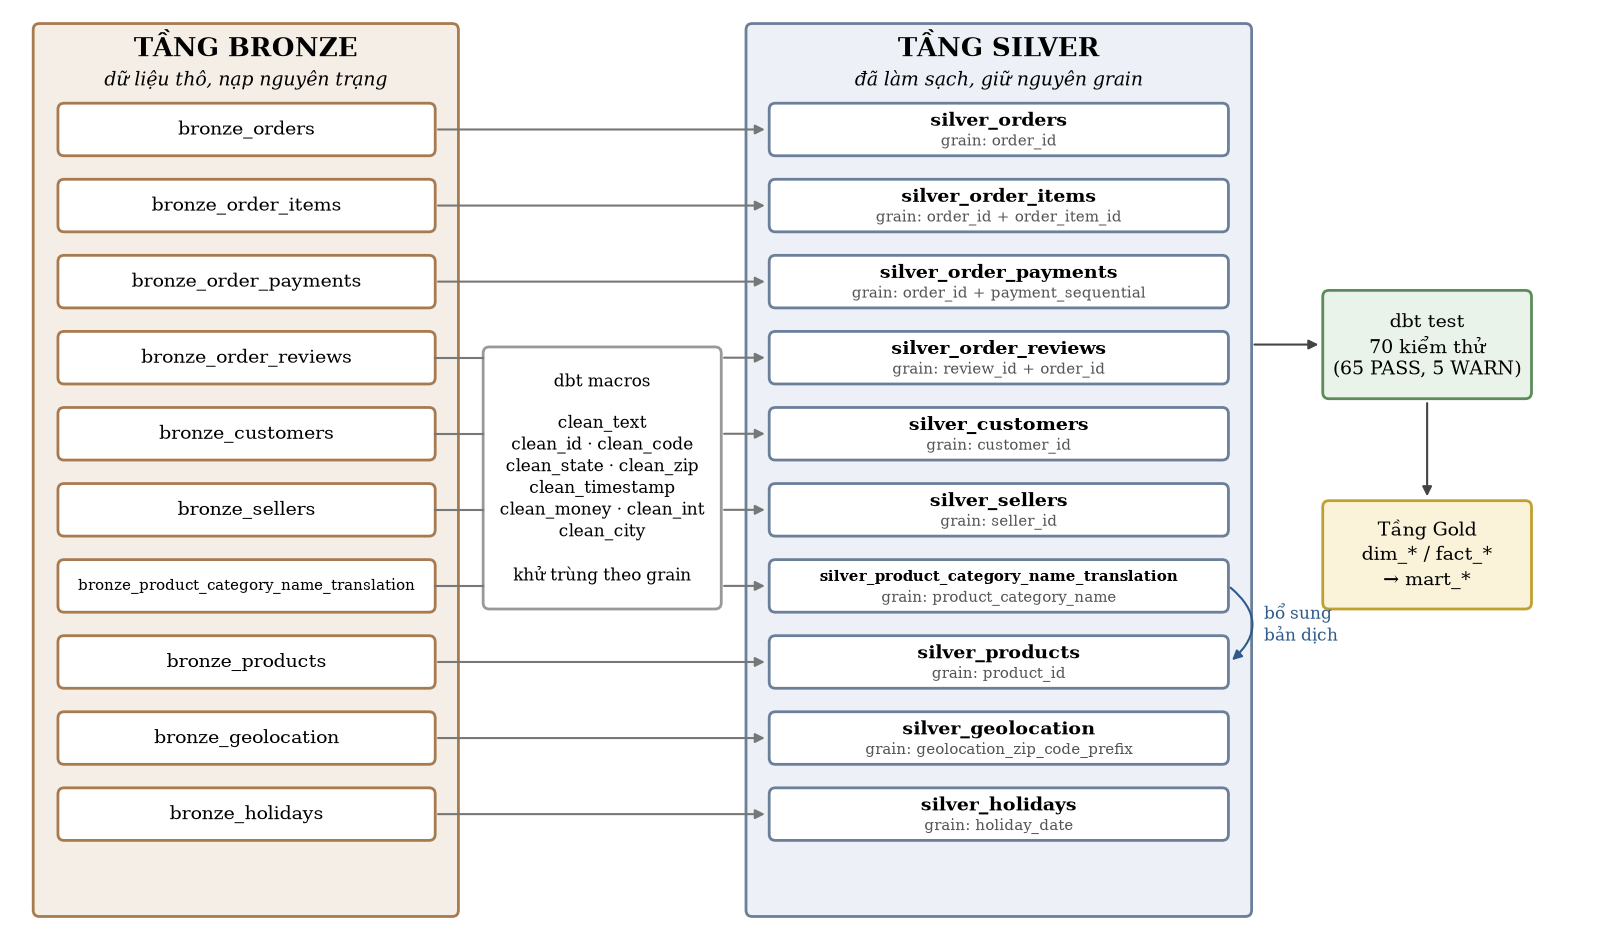

Hinh: Hinh_3.4.1_LuongXuLySilver.png


In [12]:
from src.reporting.silver_flow import draw_silver_flow

status_counts = tests['trang_thai'].value_counts()
draw_silver_flow(len(tests), int(status_counts.get('PASS', 0)), int(status_counts.get('WARN', 0)), show=True)

## 6. Kết quả

- Bảng Silver nằm trong `commerceflow.duckdb` (schema `main`), sẵn sàng cho Task D02–D03 (Gold).
- Bảng số liệu cho báo cáo mục 3.4: `reports/tables/Bang_3.4.*.csv`; hình `reports/figures/Hinh_3.4.1_LuongXuLySilver.png`.
- Kết quả kiểm thử Silver: `docs/data_quality/silver_test_results.csv`.
- File `.duckdb` không commit lên GitHub; sao lưu theo quy tắc `commerceflow_YYYYMMDD.duckdb` nếu cần chuyển cho thành viên khác.

In [13]:
print('Silver tables:')
display(recon[['bang', 'so_dong_silver']])
print('Output files:')
for p in sorted(TABLE_DIR.glob('Bang_3.4.*.csv')) + [DQ_DIR / 'silver_test_results.csv']:
    print(' -', p.relative_to(PROJECT_ROOT))

Silver tables:


,bang,so_dong_silver
0,orders,99441
1,order_items,112650
2,order_payments,103886
3,order_reviews,99224
4,customers,99441
5,sellers,3095
6,products,32951
7,product_category_name_translation,74
8,geolocation,19015
9,holidays,27


Output files:
 - reports\tables\Bang_3.4.3_DoiSoatSoDongBronzeSilver.csv
 - reports\tables\Bang_3.4.4_DoiSoatGiaTriTien.csv
 - reports\tables\Bang_3.4.5_KetQuaQuyTacLamSach.csv
 - reports\tables\Bang_3.4.6_TongHopKiemThuSilver.csv
 - docs\data_quality\silver_test_results.csv
